In [1]:
import os
from dotenv import load_dotenv
import pandas as pd
import sys
sys.path.insert(0, "/Users/jihaein/Desktop/fds_main/investment-evidence-system")

In [2]:
# Initial Set up

INITIAL_CASH = 10_000_000
COST_RATE = 0.001  # 0.1% transaction fee
CASH_DAILY_RATE = 0.000034

"""
Initially, there should be 19 stock codes listed, 
but one stock code is delisted so we drop that one temporarily so 
your first version of the engine runs on clean, gap-free data and you don’t have to solve the problem of missing data yet. 
The delisted stock code is 052270 (우전앤한단), which is a Korean stock code. 
We will add it back later when we have a solution for handling missing data.
"""

'\nInitially, there should be 19 stock codes listed, \nbut one stock code is delisted so we drop that one temporarily so \nyour first version of the engine runs on clean, gap-free data and you don’t have to solve the problem of missing data yet. \nThe delisted stock code is 052270 (우전앤한단), which is a Korean stock code. \nWe will add it back later when we have a solution for handling missing data.\n'

In [3]:
def load_daily_price() -> pd.DataFrame:
    # Load daily price & 등락률 data
    load_dotenv()

    # Get the Google Drive path
    path = os.getenv("DAILY_PRICE_DATA_DIR")
    file_path = os.path.join(path, "05_주가_일별_2015-2019.csv")

    # Read the file data
    data = pd.read_csv(file_path, header=0, skiprows=[1], dtype=str, encoding="utf-8-sig")

    data[['TDD_CLSPRC', 'CMPPREVDD_PRC', 'FLUC_RT', 'TDD_OPNPRC', 'TDD_HGPRC', 'TDD_LWPRC', 'ACC_TRDVOL', 'ACC_TRDVAL', 'MKTCAP', 'LIST_SHRS']] = data[['TDD_CLSPRC', 'CMPPREVDD_PRC', 'FLUC_RT', 'TDD_OPNPRC', 'TDD_HGPRC', 'TDD_LWPRC', 'ACC_TRDVOL', 'ACC_TRDVAL', 'MKTCAP', 'LIST_SHRS']].apply(pd.to_numeric, errors='coerce')
    data[['BAS_DD']] = data[['BAS_DD']].apply(pd.to_datetime, errors='coerce')
    data["ISU_CD"] = data["ISU_CD"].str.zfill(6)

    data = data.pivot(index='BAS_DD', columns='ISU_CD', values='FLUC_RT')

    return data

In [4]:
# testing / DO NOT INCLUDE IN THE ACTUAL PYTHON ENGINE FILE
print(load_daily_price().head(5))
print(load_daily_price().shape)
load_daily_price().isna().sum()
load_daily_price().isna().sum().sum()

ISU_CD      010170  032620  036890  038070  050540  052270  053660  059090  \
BAS_DD                                                                       
2015-01-02    1.49    1.52    0.36    0.85    1.59    2.24   -2.50   -1.34   
2015-01-05    0.56    0.38   -1.42   -0.72    0.00    1.35    2.97    0.68   
2015-01-06    2.25    0.19   -1.08   -0.85   -0.26    1.16   -1.57    5.41   
2015-01-07   -1.10    0.00    0.18    3.41    0.26   -1.97    1.07    3.85   
2015-01-08    0.56    0.56    1.09   -1.18    0.00   -3.69   -1.85   -0.31   

ISU_CD      059210  065060  065350  068790  082800  083650  089010  093190  \
BAS_DD                                                                       
2015-01-02    0.98    3.65    1.09    2.52   -1.05   -1.30    6.63    4.25   
2015-01-05    0.58    0.88   -0.65   -0.22    2.83   -1.75   -0.73   -0.45   
2015-01-06    0.39   -0.44   -0.87   -2.47    4.12    0.45    1.25   -1.36   
2015-01-07    0.19   -0.44    0.66    2.07   -2.31   -0.89   -3

np.int64(663)

In [5]:
# according to the previous data result, there are missing values for the following stock codes: 052270
col = load_daily_price()["052270"]
print("first valid:", col.first_valid_index())
print("last valid:", col.last_valid_index())

first valid: 2015-01-02 00:00:00
last valid: 2017-04-12 00:00:00


In [6]:
# data without the msing values for the stock code 052270

basket = load_daily_price().drop(columns=["052270"])

print(basket.head(5))

ISU_CD      010170  032620  036890  038070  050540  053660  059090  059210  \
BAS_DD                                                                       
2015-01-02    1.49    1.52    0.36    0.85    1.59   -2.50   -1.34    0.98   
2015-01-05    0.56    0.38   -1.42   -0.72    0.00    2.97    0.68    0.58   
2015-01-06    2.25    0.19   -1.08   -0.85   -0.26   -1.57    5.41    0.39   
2015-01-07   -1.10    0.00    0.18    3.41    0.26    1.07    3.85    0.19   
2015-01-08    0.56    0.56    1.09   -1.18    0.00   -1.85   -0.31    1.35   

ISU_CD      065060  065350  068790  082800  083650  089010  093190  096350  \
BAS_DD                                                                       
2015-01-02    3.65    1.09    2.52   -1.05   -1.30    6.63    4.25   -1.31   
2015-01-05    0.88   -0.65   -0.22    2.83   -1.75   -0.73   -0.45   -1.52   
2015-01-06   -0.44   -0.87   -2.47    4.12    0.45    1.25   -1.36    0.00   
2015-01-07   -0.44    0.66    2.07   -2.31   -0.89   -3.61    0

In [7]:
# STEP 2: The day-0 setup
# 최초 총매수 금액
n = len(basket.columns) # number of stock codes listed

investable = INITIAL_CASH / (1 + COST_RATE)

# 종목별 매수금액 
per_stock = investable / n

# 최초 매수거래비용
entry_cost = investable * COST_RATE # ~ 9,990.0

# 현금 잔액 
cash = INITIAL_CASH - investable - entry_cost # should land on 0

In [8]:
# representing holdings
holdings = pd.Series(data=per_stock, index=basket.columns)
print(holdings.head(5))

W0 = holdings.sum() + cash
print("W0:  ", W0)      # expect ≈ 9,990,009.99
print("cash:", cash)    # expect ≈ 0

ISU_CD
010170    555000.555001
032620    555000.555001
036890    555000.555001
038070    555000.555001
050540    555000.555001
dtype: float64
W0:   9990009.99000999
cash: -1.44427758641541e-09


In [9]:
# The daily loop  (무손절 version)

# get the days to walk
dates = basket.index[basket.index >= '2016-01-04']  # start from the first trading day of 2016
holdings = pd.Series(per_stock, index=basket.columns)

# print(dates)

records = []
for date in dates: 
    holdings = holdings * (1 + basket.loc[date] / 100)
    W = holdings.sum() + cash
    # print(f"{date}: {W:,.2f}")
    records.append(W)

ser_buyhold = pd.Series(data=records, index=dates)

print(ser_buyhold.head(5))

BAS_DD
2016-01-04    9.958375e+06
2016-01-05    9.983004e+06
2016-01-06    9.942852e+06
2016-01-07    9.796474e+06
2016-01-08    9.867164e+06
dtype: float64


11303193.981185427


/Users/jihaein/Desktop/fds_main/investment-evidence-system/.venv/lib/python3.14/site-packages/IPython/core/events.py:101: UserWarning: Glyph 47924 (\N{HANGUL SYLLABLE MU}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
/Users/jihaein/Desktop/fds_main/investment-evidence-system/.venv/lib/python3.14/site-packages/IPython/core/events.py:101: UserWarning: Glyph 49552 (\N{HANGUL SYLLABLE SON}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
/Users/jihaein/Desktop/fds_main/investment-evidence-system/.venv/lib/python3.14/site-packages/IPython/core/events.py:101: UserWarning: Glyph 51208 (\N{HANGUL SYLLABLE JEOL}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
/Users/jihaein/Desktop/fds_main/investment-evidence-system/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 47924 (\N{HANGUL SYLLABLE MU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/jihaein/Desktop/fds_main/investment-evidence-sys

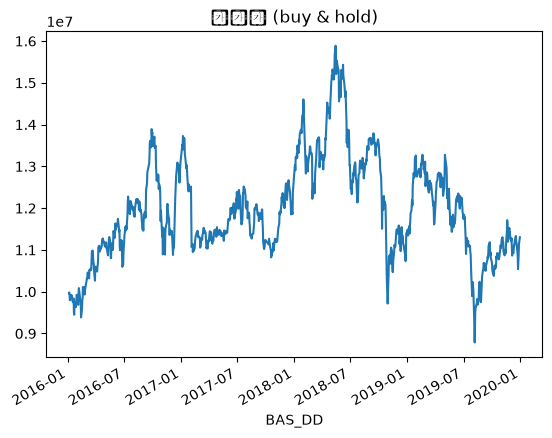

In [10]:
ser_buyhold.plot(title="무손절 (buy & hold)")
print(ser_buyhold.iloc[-1])   # final portfolio value, end of 2019

In [11]:
# Step 4: Selling

# sell_schedule = {"036890": pd.Timestamp("2017-06-30")}
sell_schedule = {}

holdings = pd.Series(per_stock, index=basket.columns)
cash = 0

records = []
for date in dates:
    # mark-to-market the holdings
    holdings = holdings * (1 + basket.loc[date] / 100)

    # sell
    to_sell = [s for s, d in sell_schedule.items() if d == date]
    for s in to_sell:
        proceeds = holdings[s]
        sell_cost = proceeds * COST_RATE
        cash += proceeds - sell_cost
        holdings[s] = 0 # gone; from now it sits in cash, not the market
    # record W
    W = holdings.sum() + cash
    records.append(W)

ser_sell = pd.Series(data=records, index=dates)

In [12]:
# Step 5: 현금일별수익률
holdings = pd.Series(per_stock, index=basket.columns)
cash = 0

# testing
sell_schedule = {"036890": pd.Timestamp("2017-06-30")}

records = []
for date in dates:
    # update cash with daily interest
    cash = cash * (1 + CASH_DAILY_RATE)

    # mark-to-market the holdings
    holdings = holdings * (1 + basket.loc[date] / 100)

    # process sells
    to_sell = [s for s, d in sell_schedule.items() if d == date]
    for s in to_sell:
        proceeds = holdings[s]
        sell_cost = proceeds * COST_RATE
        cash += proceeds - sell_cost
        holdings[s] = 0 # gone; from now it sits in cash, not the market

    # record W
    W = holdings.sum() + cash
    print(f"{date}: {W:,.2f}")
    records.append(W)

ser_sell_cash = pd.Series(data=records, index=dates)

2016-01-04 00:00:00: 9,958,374.96
2016-01-05 00:00:00: 9,983,004.13
2016-01-06 00:00:00: 9,942,852.25
2016-01-07 00:00:00: 9,796,473.60
2016-01-08 00:00:00: 9,867,164.39
2016-01-11 00:00:00: 9,911,366.73
2016-01-12 00:00:00: 9,885,045.17
2016-01-13 00:00:00: 9,914,795.90
2016-01-14 00:00:00: 9,835,536.03
2016-01-15 00:00:00: 9,779,806.18
2016-01-18 00:00:00: 9,745,586.29
2016-01-19 00:00:00: 9,837,255.42
2016-01-20 00:00:00: 9,499,003.62
2016-01-21 00:00:00: 9,448,955.49
2016-01-22 00:00:00: 9,676,984.01
2016-01-25 00:00:00: 9,746,486.26
2016-01-26 00:00:00: 9,630,029.00
2016-01-27 00:00:00: 9,708,127.52
2016-01-28 00:00:00: 9,830,368.70
2016-01-29 00:00:00: 9,927,727.87
2016-02-01 00:00:00: 9,867,370.73
2016-02-02 00:00:00: 9,730,306.53
2016-02-03 00:00:00: 9,686,106.54
2016-02-04 00:00:00: 9,976,746.46
2016-02-05 00:00:00: 10,085,951.64
2016-02-11 00:00:00: 9,709,642.00
2016-02-12 00:00:00: 9,384,650.35
2016-02-15 00:00:00: 9,579,480.91
2016-02-16 00:00:00: 9,795,979.43
2016-02-17 00

In [13]:
# step 6: putting everything together in a function
def run_strategy(basket, sell_schedule):    
    
    # 1. day-0 setup   ← your Step 2 code (compute n, investable, per_stock, holdings, cash)
    n = len(basket.columns) # number of stock codes listed
    investable = INITIAL_CASH / (1 + COST_RATE)

    # 종목별 매수금액 
    per_stock = investable / n

    # 최초 매수거래비용
    entry_cost = investable * COST_RATE # ~ 9,990.0

    # 현금 잔액 
    cash = INITIAL_CASH - investable - entry_cost # should land on 0

    # 보유가치
    holdings = pd.Series(data=per_stock, index=basket.columns)

    # 2. daily loop  (dates, the loop, record W)

    # get the days to walk
    dates = basket.index[basket.index >= '2016-01-04']  # start from the first trading day of 2016

    records = []
    for date in dates:
        # update cash with daily interest
        cash = cash * (1 + CASH_DAILY_RATE)

        # mark-to-market the holdings
        holdings = holdings * (1 + basket.loc[date] / 100)

        # process sells
        to_sell = [s for s, d in sell_schedule.items() if d == date]
        for s in to_sell:
            proceeds = holdings[s]
            sell_cost = proceeds * COST_RATE
            cash += proceeds - sell_cost
            holdings[s] = 0 # gone; from now it sits in cash, not the market

        # record W
        W = holdings.sum() + cash
        records.append(W)
    ser_sell_cash = pd.Series(data=records, index=dates)
    return ser_sell_cash


In [14]:
run_strategy(basket, {}).equals(ser_buyhold)


True

In [15]:
run_strategy(basket, {"036890": pd.Timestamp("2017-06-30")}).equals(ser_sell_cash)

False